In [1]:
import batoid
import batoid_rubin
import numpy as np

from galsim.zernike import zernikeRotMatrix

In [2]:
from lsst.ts.wep.task import DonutStamp, DonutStamps
from lsst.afw.image import MaskedImageF, ImageF
from lsst.geom import SpherePoint, radians, Point2D
from lsst.afw.cameraGeom import FIELD_ANGLE, PIXELS

from lsst.obs.lsst import LsstComCam, LsstCam
from lsst.ts.wep.task import CalcZernikesTask, CalcZernikesTaskConfig
from lsst.ts.wep.task import EstimateZernikesTieTask, EstimateZernikesTieConfig
from lsst.ts.wep.task import EstimateZernikesDanishTask, EstimateZernikesDanishConfig

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
comcamFiducial = batoid.Optic.fromYaml("ComCam_i.yaml")
comcam = LsstComCam().getCamera()

lsstFiducial = batoid.Optic.fromYaml("LSST_i.yaml")
lsstcam = LsstCam().getCamera()

In [5]:
class CalcCoords:
    def __init__(self, camera):
        self.camera = camera

    def __call__(
        self,
        thx=None, thy=None,  # batoid field angle (radians)
        afwx=None, afwy=None,  afwsys=None,  # afw cameraGeom x, y, coordsys
        det=None,
        rtp=0.0,
    ):
        srtp, crtp = np.sin(rtp), np.cos(rtp)
    
        # Special case: everything is None
        if all(v is None for v in [thx, thy, afwx, afwy, det]):
            thx = 0.0
            thy = 0.0
        elif all(v is None for v in [thx, thy, afwx, afwy]) and det is not None:
            afwsys = PIXELS
            afwx, afwy = det.getCenter(PIXELS)
        
        # Convert to afw field angle if needed
        if thx is not None or thy is not None:
            afwx = -srtp*thx + crtp*thy
            afwy = crtp*thx + srtp*thy
            afwsys = FIELD_ANGLE
        
        # Have afwx, afwy, afwsys now.  If needed, find closest detector.
        if det is None:
            dists = []
            for det in self.camera:
                center = det.getCenter(afwsys)
                dists.append((
                    det,
                    np.hypot(afwx-center.x, afwy-center.y)
                ))
            best = min(dists, key=lambda t:t[1])
            det = best[0]
    
        # Now have afwx, afwy, afwsys, det.  Assemble output.
        if thx is None or thy is None:
            fromSys = det.makeCameraSys(afwsys)
            toSys = det.makeCameraSys(FIELD_ANGLE)
            fax, fay = self.camera.transform(Point2D(afwx, afwy), fromSys, toSys)
            thx = -srtp*fax + crtp*fay
            thy = crtp*fax + srtp*fay
    
        if afwsys == PIXELS:
            px, py = afwx, afwy
        else:
            fromSys = det.makeCameraSys(afwsys)
            toSys = det.makeCameraSys(PIXELS)
            px, py = self.camera.transform(Point2D(afwx, afwy), fromSys, toSys)
        return dict(
            thx=thx, 
            thy=thy,
            det=det,
            name=det.getName(),
            px=px, 
            py=py
        )        

In [6]:
class Simulator:
    def __init__(
        self,
        camera,
        defocal_length=0.0015, # meters
        defocal_optic="ComCam",
        rot_optic="ComCam",
        focal_stamp_size=21,
        donut_stamp_size=181
    ):
        self.camera = camera
        self.defocal_length = defocal_length
        self.defocal_optic = defocal_optic
        self.rot_optic = rot_optic
        self.focal_stamp_size = focal_stamp_size
        self.donut_stamp_size = donut_stamp_size
        self.cc = CalcCoords(camera)
    
    def makeStamps(
        self,
        telescope,
        thx=None, thy=None,  # batoid field angle (radians)
        afwx=None, afwy=None,  afwsys=None,  # afw cameraGeom x, y, coordsys
        det=None,
        rtp=0.0,
        nphot=500_000, 
        background_sigma=4.0,
        seeing=0.6,
        focus='intra',
        rng=None
    ):
        if rng is None:
            rng = np.random.default_rng()

        coords = self.cc(
            thx=thx, thy=thy,
            afwx=afwx, afwy=afwy, afwsys=afwsys,
            det=det,
            rtp=rtp
        )
        thx = coords['thx']
        thy = coords['thy']
        det = coords['det']
        px = coords['px']
        py = coords['py']
        
        if focus == 'focal':
            stamp_size = self.focal_stamp_size
        elif focus == 'intra':
            stamp_size = self.donut_stamp_size
            telescope = telescope.withLocallyShiftedOptic(
                self.defocal_optic, 
                [0, 0, -self.defocal_length]
            )
        elif focus == 'extra':
            stamp_size = self.donut_stamp_size
            telescope = telescope.withLocallyShiftedOptic(
                self.defocal_optic, 
                [0, 0, +self.defocal_length]
            )
        telescope = telescope.withLocallyRotatedOptic(
            self.rot_optic,
            batoid.RotZ(rtp)
        )
        so2 = stamp_size // 2
        histrange = [[-so2*10e-6, so2*10e-6], [-so2*10e-6, so2*10e-6]]

        rv = batoid.RayVector.asPolar(
            optic=telescope,
            wavelength=754e-9,  # Hard coding i-band for now
            nrandom=nphot,
            rng=rng,
            theta_x=thx,
            theta_y=thy,
        )
        telescope.trace(rv)
        xmid = np.mean(rv.x[~rv.vignetted])
        ymid = np.mean(rv.y[~rv.vignetted])
        xmid = (xmid // 10e-6) * 10e-6  # Lock to pixel grid
        ymid = (ymid // 10e-6) * 10e-6  # Lock to pixel grid        
            
        x, y = rv.x, rv.y
        x -= xmid
        y -= ymid
        # Convolve in a Gaussian
        scale = 10e-6 * seeing/2.35/0.2
        x += rng.normal(scale=scale, size=len(x))
        y += rng.normal(scale=scale, size=len(y))
        
        # Bin rays
        hist, _, _ = np.histogram2d(
            y[~rv.vignetted], x[~rv.vignetted], bins=stamp_size,
            range=histrange,
        )
        image = np.ascontiguousarray(hist.astype(np.float32).T)
        image += rng.normal(scale=background_sigma, size=image.shape).astype(np.float32)
        var = np.full_like(image, background_sigma**2)
        mi = MaskedImageF(ImageF(image), variance=ImageF(var))
        stamp = DonutStamp(
            stamp_im=mi,
            sky_position=SpherePoint(0.0, 0.0, radians),
            centroid_position=Point2D(px, py),
            blend_centroid_positions=np.array([["nan"], ["nan"]], dtype=float).T,
            defocal_type=focus,
            defocal_distance=self.defocal_length*1e3,  # m -> mm
            detector_name=det.getName(),
            cam_name=self.camera.getName(),
            bandpass="i",
        )
    
        stamps = DonutStamps([stamp])
        return stamps        

In [7]:
comcamSimulator = Simulator(comcam)
lsstcamSimulator = Simulator(lsstcam, defocal_optic="LSSTCamera", rot_optic="LSSTCamera")

In [8]:
def test_zk(
    simulator, 
    fiducial, 
    izk, 
    amp, 
    thx=None, thy=None,
    afwx=None, afwy=None, afwsys=None,
    det=None,
    rtp=0, 
    seeing=0.7, 
    nphot=500_000,
    background_sigma=4.0,
    verbose=False
):
    coords = simulator.cc(
        thx=thx, thy=thy,
        afwx=afwx, afwy=afwy, afwsys=afwsys,
        det=det,
        rtp=rtp
    )
    thx = coords['thx']
    thy = coords['thy']

    builder = batoid_rubin.LSSTBuilder(fiducial)
    builder = builder.with_extra_zk([0]*izk+[amp*1e-6], eps=0.612)
    telescope = builder.build()
    intraStamps = simulator.makeStamps(
        telescope, 
        thx=thx, thy=thy, 
        rtp=rtp, focus='intra', 
        seeing=seeing, nphot=nphot, background_sigma=background_sigma
    )
    extraStamps = simulator.makeStamps(
        telescope, 
        thx=thx, thy=thy, 
        rtp=rtp, focus='extra',
        seeing=seeing, nphot=nphot, background_sigma=background_sigma
    )

    tieConfig = CalcZernikesTaskConfig()
    tieConfig.estimateZernikes.retarget(EstimateZernikesTieTask)
    tieConfig.estimateZernikes.maxNollIndex=28
    if simulator.defocal_optic == "ComCam":
        tieConfig.estimateZernikes.instConfigFile="policy:instruments/ComCam.yaml"
    elif simulator.defocal_optic == "LSSTCamera":
        tieConfig.estimateZernikes.instConfigFile="policy:instruments/LsstFamCam.yaml"
    elif simulator.defocal_optic == "Detector":
        tieConfig.estimateZernikes.instConfigFile="policy:instruments/LsstCam.yaml"        
    tieTask = CalcZernikesTask(config=tieConfig)
    tieResult = tieTask.run(intraStamps, extraStamps)
    tieZkAvg = tieResult.outputZernikesAvg
    tieZkRaw = tieResult.outputZernikesRaw

    danishConfig = CalcZernikesTaskConfig()
    danishConfig.estimateZernikes.retarget(EstimateZernikesDanishTask)
    danishConfig.estimateZernikes.maxNollIndex=28
    if simulator.defocal_optic == "ComCam":
        danishConfig.estimateZernikes.instConfigFile="policy:instruments/ComCam.yaml"
    elif simulator.defocal_optic == "LSSTCamera":
        danishConfig.estimateZernikes.instConfigFile="policy:instruments/LsstFamCam.yaml"
    elif simulator.defocal_optic == "Detector":
        danishConfig.estimateZernikes.instConfigFile="policy:instruments/LsstCam.yaml"        
    danishTask = CalcZernikesTask(config=danishConfig)
    danishResult = danishTask.run(intraStamps, extraStamps)
    danishZkAvg = danishResult.outputZernikesAvg
    danishZkRaw = danishResult.outputZernikesRaw

    zk = batoid.zernike(
        telescope,
        thx, thy,
        753.9e-9,
        nx=128, jmax=28, eps=0.61
    )*0.7539 # => micron
    # Rotate into camera frame where ts_wep operates.
    rot = zernikeRotMatrix(28, -rtp)
    zk = rot@zk
    zk = zk[4:]
    
    if verbose:
        del coords['det']
        print(coords)
        print(" j      TIE   Danish    Truth")
        print("=============================")
        for j in range(4, 29):
            print(f"{j:2d} {tieZkAvg[0,j-4]:8.4f} {danishZkAvg[0,j-4]:8.4f} {zk[j-4]:8.4f}")
        fig, axes = plt.subplots(ncols=2, figsize=(10, 5))
        axes[0].imshow(intraStamps[0].stamp_im.image.array)
        axes[1].imshow(extraStamps[0].stamp_im.image.array)
        plt.show()
    return {"tie":tieZkAvg, "danish":danishZkAvg, "truth":zk}

{'thx': -9.705063726710865e-07, 'thy': -9.705063726713756e-07, 'name': 'R22_S11', 'px': 2035.5, 'py': 1999.5}
 j      TIE   Danish    Truth
 4  -0.0048  -0.0543  -0.0980
 5   0.0837   0.0387  -0.0000
 6  -0.0440  -0.0341   0.0000
 7   0.0038  -0.0197   0.0000
 8   0.0132   0.0054   0.0000
 9  -0.0005  -0.0230  -0.0000
10  -0.9712  -0.9889  -0.9983
11   0.0525   0.0443   0.0353
12   0.0187   0.0192  -0.0000
13  -0.0099  -0.0068   0.0000
14  -0.0135  -0.0170  -0.0000
15  -0.0125   0.0057   0.0000
16   0.0040  -0.0001  -0.0000
17   0.0028   0.0051  -0.0000
18   0.0049   0.0021   0.0000
19   0.0082   0.0052  -0.0000
20   0.0191   0.0037  -0.0000
21   0.0066   0.0065   0.0000
22   0.0086   0.0130   0.0131
23   0.0022   0.0007   0.0000
24  -0.0024  -0.0035  -0.0000
25  -0.0025  -0.0020  -0.0000
26   0.0043   0.0061  -0.0001
27   0.0131  -0.0054   0.0000
28   0.0042   0.0018  -0.0000


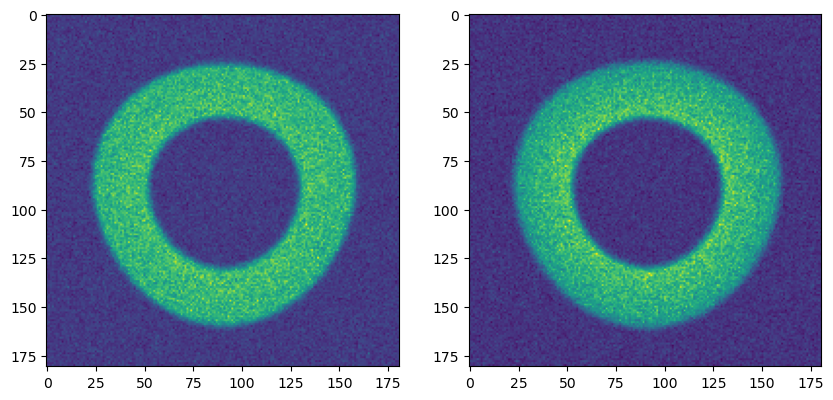

In [9]:
# Try adding 1 micron of Z10
_ = test_zk(comcamSimulator, comcamFiducial, izk=10, amp=1.0, det=comcam['R22_S11'], verbose=True)

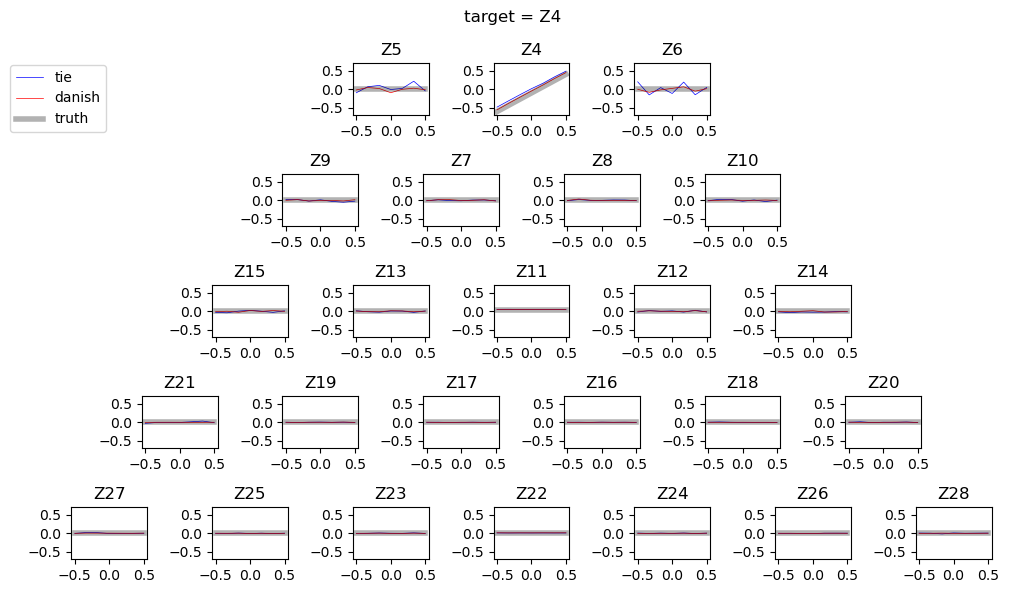

In [10]:
# Zernike pyramid layout from Z4 to Z28
layout = [
    [0,0,0,0,         5,5,   4,4,   6,6,     0,0,0,0],
    [0,0,0,       9,9,   7,7,   8,8,  10,10,   0,0,0],
    [0,0,    15,15, 13,13, 11,11, 12,12, 14,14,  0,0],
    [0,  21,21, 19,19, 17,17, 16,16, 18,18, 20,20, 0],
    [27,27, 25,25, 23,23, 22,22, 24,24, 26,26, 28,28]
]

# for k in range(4, 29):
for k in range(4, 5):
    results = []
    amps = np.linspace(-0.5, 0.5, num=7)
    for amp in amps:
        results.append(test_zk(comcamSimulator, comcamFiducial, k, -amp, det=comcam['R22_S11']))

    fig, axd = plt.subplot_mosaic(layout, figsize=(10, 6), empty_sentinel=0)
    for j in range(4, 29):
        ax = axd[j]
        ax.plot(amps, [r["tie"][0,j-4] for r in results], c='b', label="tie", lw=0.5)
        ax.plot(amps, [r["danish"][0,j-4] for r in results], c='r', label="danish", lw=0.5)
        ax.plot(amps, [r["truth"][j-4] for r in results], c='k', label="truth", lw=4, alpha=0.3)
        ax.set_ylim(-0.7, 0.7)
        ax.set_title(f"Z{j}")
    handles, labels = axd[4].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(0.1, 0.9), bbox_transform=fig.transFigure)
    fig.suptitle(f"target = Z{k}")
    fig.tight_layout()
    plt.show()

In [11]:
ranges = [
    100,          # M2 dz
    3000, 3000,   # M2 dx/dy
    70, 70,       # M2 rx/ry
    100,          # cam dz
    5000, 5000,   # cam dx/dy
    200, 200,     # cam rx/ry
    1, 1, 1,      # M1M3 0-2
    0.75, 0.75,   #      3-4
    1, 1,         #      5-6
    0.5, 0.5, 0.5, 0.5, 0.5, # 7-11
    0.4, 0.4,     # 12-13
    0.5, 0.5,     # 14-15
    0.4, 0.4,     # 16-17
    0.3,          # 18
    0.5,          # 19
    1, 1, 1, 1,   # M2 0-3
    0.5,          # 4
    1, 1,         # 5-6
    0.5, 0.5, 0.5, 0.5, 0.5, 0.5, # 7-12
    0.4, 0.4,     # 13-14
    0.3, 0.3,     # 15-16
    0.1,
    0.2, 0.2      # 18, 19
]

In [12]:
def test_dof(
    simulator, 
    fiducial, 
    idof, 
    amp, 
    thx=None, thy=None,
    afwx=None, afwy=None, afwsys=None,
    det=None,
    rtp=0, 
    seeing=0.7, 
    nphot=500_000,
    background_sigma=4.0,
    verbose=False
):
    coords = simulator.cc(
        thx=thx, thy=thy,
        afwx=afwx, afwy=afwy, afwsys=afwsys,
        det=det,
        rtp=rtp
    )
    thx = coords['thx']
    thy = coords['thy']

    builder = batoid_rubin.LSSTBuilder(fiducial)
    builder = builder.with_aos_dof([0]*idof+[amp]+[0]*(50-idof-1))
    telescope = builder.build()
    intraStamps = simulator.makeStamps(
        telescope, 
        thx=thx, thy=thy, 
        rtp=rtp, focus='intra', 
        seeing=seeing, nphot=nphot, background_sigma=background_sigma
    )
    extraStamps = simulator.makeStamps(
        telescope, 
        thx=thx, thy=thy, 
        rtp=rtp, focus='extra',
        seeing=seeing, nphot=nphot, background_sigma=background_sigma
    )

    tieConfig = CalcZernikesTaskConfig()
    tieConfig.estimateZernikes.retarget(EstimateZernikesTieTask)
    tieConfig.estimateZernikes.maxNollIndex=28
    if simulator.defocal_optic == "ComCam":
        tieConfig.estimateZernikes.instConfigFile="policy:instruments/ComCam.yaml"
    elif simulator.defocal_optic == "LSSTCamera":
        tieConfig.estimateZernikes.instConfigFile="policy:instruments/LsstFamCam.yaml"
    elif simulator.defocal_optic == "Detector":
        tieConfig.estimateZernikes.instConfigFile="policy:instruments/LsstCam.yaml"        
    tieTask = CalcZernikesTask(config=tieConfig)
    tieResult = tieTask.run(intraStamps, extraStamps)
    tieZkAvg = tieResult.outputZernikesAvg
    tieZkRaw = tieResult.outputZernikesRaw

    danishConfig = CalcZernikesTaskConfig()
    danishConfig.estimateZernikes.retarget(EstimateZernikesDanishTask)
    danishConfig.estimateZernikes.maxNollIndex=28
    if simulator.defocal_optic == "ComCam":
        danishConfig.estimateZernikes.instConfigFile="policy:instruments/ComCam.yaml"
    elif simulator.defocal_optic == "LSSTCamera":
        danishConfig.estimateZernikes.instConfigFile="policy:instruments/LsstFamCam.yaml"
    elif simulator.defocal_optic == "Detector":
        danishConfig.estimateZernikes.instConfigFile="policy:instruments/LsstCam.yaml"        
    danishTask = CalcZernikesTask(config=danishConfig)
    danishResult = danishTask.run(intraStamps, extraStamps)
    danishZkAvg = danishResult.outputZernikesAvg
    danishZkRaw = danishResult.outputZernikesRaw
    
    zk = batoid.zernike(
        telescope,
        0.0, 0.0,
        753.9e-9,
        nx=128, jmax=28, eps=0.61
    )*0.7539 # => micron

    zk = batoid.zernike(
        telescope,
        thx, thy,
        753.9e-9,
        nx=128, jmax=28, eps=0.61
    )*0.7539 # => micron
    # Rotate into camera frame where ts_wep operates.
    rot = zernikeRotMatrix(28, -rtp)
    zk = rot@zk
    zk = zk[4:]

    if verbose:
        del coords['det']
        print(coords)
        print(" j      TIE   Danish    Truth")
        print("=============================")
        for j in range(4, 29):
            print(f"{j:2d} {tieZkAvg[0,j-4]:8.4f} {danishZkAvg[0,j-4]:8.4f} {zk[j-4]:8.4f}")
        fig, axes = plt.subplots(ncols=2, figsize=(10, 5))
        axes[0].imshow(intraStamps[0].stamp_im.image.array)
        axes[1].imshow(extraStamps[0].stamp_im.image.array)
        plt.show()

    return {"tie":tieZkAvg, "danish":danishZkAvg, "truth":zk}

{'thx': -9.705063726710865e-07, 'thy': -9.705063726713756e-07, 'name': 'R22_S11', 'px': 2035.5, 'py': 1999.5}
 j      TIE   Danish    Truth
 4   0.0106  -0.0871  -0.0976
 5  -0.0686  -0.0198   0.0003
 6   0.0377   0.0189  -0.0008
 7  -0.0129  -0.0163  -0.0062
 8  -0.4899  -1.0061  -1.6458
 9  -0.0510  -0.0090  -0.0012
10  -0.0059  -0.0140   0.0022
11   0.0502   0.0381   0.0352
12   0.0001  -0.0048   0.0004
13   0.0095   0.0049   0.0001
14  -0.0110   0.0074   0.0012
15   0.0340   0.0052   0.0010
16   0.0664   0.1356   0.2798
17  -0.0008   0.0020   0.0010
18  -0.0070   0.0006  -0.0017
19  -0.0055   0.0026   0.0000
20   0.0038   0.0051  -0.0047
21  -0.0088  -0.0016  -0.0008
22   0.0089   0.0129   0.0132
23  -0.0020  -0.0005   0.0000
24   0.0026   0.0031  -0.0001
25  -0.0006  -0.0023  -0.0002
26  -0.0049  -0.0019  -0.0001
27   0.0234   0.0019   0.0001
28   0.0055   0.0022   0.0001


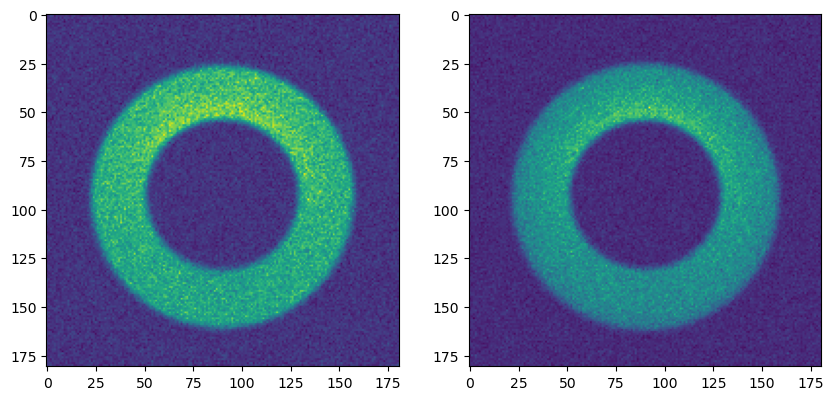

In [13]:
_ = test_dof(comcamSimulator, comcamFiducial, 15, 1.0, det=comcam['R22_S11'], verbose=True)

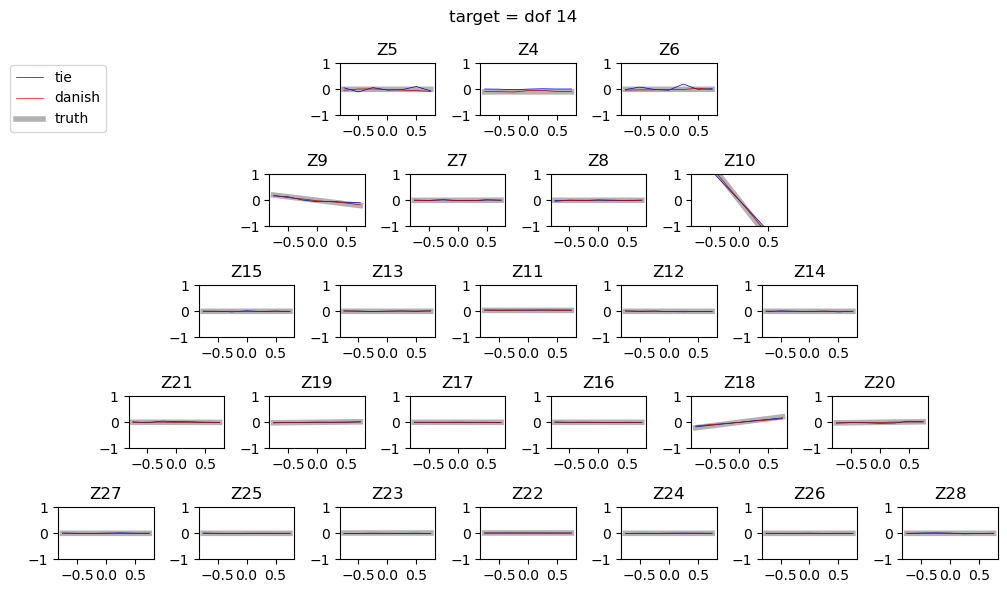

In [14]:
# Zernike pyramid layout from Z4 to Z28
layout = [
    [0,0,0,0,         5,5,   4,4,   6,6,     0,0,0,0],
    [0,0,0,       9,9,   7,7,   8,8,  10,10,   0,0,0],
    [0,0,    15,15, 13,13, 11,11, 12,12, 14,14,  0,0],
    [0,  21,21, 19,19, 17,17, 16,16, 18,18, 20,20, 0],
    [27,27, 25,25, 23,23, 22,22, 24,24, 26,26, 28,28]
]

# for k in range(0, 50):
for k in range(14, 15):
    results = []
    amps = ranges[k]*np.linspace(-1, 1, num=7)
    for amp in amps:
        results.append(test_dof(comcamSimulator, comcamFiducial, k, amp, det=comcam['R22_S11']))

    fig, axd = plt.subplot_mosaic(layout, figsize=(10, 6), empty_sentinel=0)
    for j in range(4, 29):
        ax = axd[j]
        ax.plot(amps, [r["tie"][0,j-4] for r in results], c='b', label="tie", lw=0.5)
        ax.plot(amps, [r["danish"][0,j-4] for r in results], c='r', label="danish", lw=0.5)
        ax.plot(amps, [r["truth"][j-4] for r in results], c='k', label="truth", lw=4, alpha=0.3)

        ax.set_ylim(-1.0, 1.0)
        ax.set_title(f"Z{j}")
    handles, labels = axd[4].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(0.1, 0.9), bbox_transform=fig.transFigure)
    fig.suptitle(f"target = dof {k}")
    fig.tight_layout()
    plt.show()